<a href="https://colab.research.google.com/github/shaxamillion/NBA-Standings-Stabilization-Analysis/blob/main/NBA_Standings_Stabilization_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# CELL 1 | LOAD THE DATA | run first
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

URL_538 = "https://raw.githubusercontent.com/fivethirtyeight/data/master/nba-elo/nbaallelo.csv"
URL_HOOPR = "https://raw.githubusercontent.com/sportsdataverse/hoopR-nba-data/main/nba/schedules/parquet/nba_schedule_{y}.parquet"

# Season END year: 2015 means 2014-15, 2026 means 2025-26, 2027 means the current 2026-27 season.
SKIP_YEARS = {1999, 2012, 2013, 2020, 2021}   # lockouts, 2013 cancelled game, COVID seasons
ANALYSIS_START = 1990                          # set to 2016 to analyze only the modern era

# 1990-2015: FiveThirtyEight game history
raw = pd.read_csv(URL_538)
raw = raw[(raw["is_playoffs"] == 0) & raw["year_id"].between(1990, 2015)]
old = pd.DataFrame({
    "SEASON": raw["year_id"],
    "TEAM_ABBREVIATION": raw["team_id"],
    "GAME_NUM": raw["seasongame"],
    "WL": np.where(raw["game_result"] == "W", "W", "L"),
})

# 2016-2026 (and the current season): hoopR / ESPN schedule files
def load_hoopr(y):
    d = pd.read_parquet(URL_HOOPR.format(y=y))
    d = d[(d["season_type"] == 2) & (d["type_abbreviation"] == "STD") & d["status_type_completed"].astype(bool)]
    d = d.sort_values("date")
    home_won = d["home_score"].astype(float) > d["away_score"].astype(float)
    home = pd.DataFrame({"TEAM_ABBREVIATION": d["home_abbreviation"], "date": d["date"],
                         "WL": np.where(home_won, "W", "L")})
    away = pd.DataFrame({"TEAM_ABBREVIATION": d["away_abbreviation"], "date": d["date"],
                         "WL": np.where(home_won, "L", "W")})
    long = pd.concat([home, away]).sort_values(["TEAM_ABBREVIATION", "date"])
    long["GAME_NUM"] = long.groupby("TEAM_ABBREVIATION").cumcount() + 1
    long["SEASON"] = y
    return long[["SEASON", "TEAM_ABBREVIATION", "GAME_NUM", "WL"]]

new = pd.concat([load_hoopr(y) for y in range(2016, 2027) if y not in SKIP_YEARS], ignore_index=True)
games = pd.concat([old, new], ignore_index=True)
print(f"Loaded {len(games):,} team-games across {games['SEASON'].nunique()} seasons")

g = games[~games["SEASON"].isin(SKIP_YEARS) & (games["SEASON"] >= ANALYSIS_START)].copy()
g = g.sort_values(["SEASON", "TEAM_ABBREVIATION", "GAME_NUM"]).reset_index(drop=True)

g["W"] = (g["WL"] == "W").astype(int)
grp = g.groupby(["SEASON", "TEAM_ABBREVIATION"])
g["N"] = grp.cumcount() + 1
g["cumW"] = grp["W"].cumsum()
g["wp"] = g["cumW"] / g["N"]

# Keep only team-seasons with a complete 82 games (this also drops All-Star exhibition "teams")
full = grp["N"].transform("max") == 82
g = g[full].copy()

final = g[g["N"] == 82][["SEASON", "TEAM_ABBREVIATION", "cumW"]].rename(columns={"cumW": "final_W"})
final["final_wp"] = final["final_W"] / 82
final["final_rank"] = final.groupby("SEASON")["final_wp"].rank(method="min", ascending=False)

g = g.merge(final, on=["SEASON", "TEAM_ABBREVIATION"])
g["rest_wp"] = np.where(g["N"] < 82, (g["final_W"] - g["cumW"]) / (82 - g["N"]), np.nan)
g["rank_N"] = g.groupby(["SEASON", "N"])["wp"].rank(method="min", ascending=False)

print(f"{g['SEASON'].nunique()} seasons, {g[['SEASON','TEAM_ABBREVIATION']].drop_duplicates().shape[0]} team-seasons")

Loaded 82,486 team-games across 35 seasons
32 seasons, 934 team-seasons


In [2]:
# CELL 2 | ENGINE: reliability, forecasts, rankings, bootstrap | run second (takes a minute)
import numpy as np, pandas as pd, warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)

# ---------- 1) per-game wins AND point margins for every team-season ----------
old_m = pd.DataFrame({"SEASON": raw["year_id"], "TEAM_ABBREVIATION": raw["team_id"],
                      "GAME_NUM": raw["seasongame"], "MARGIN": raw["pts"] - raw["opp_pts"]})

def load_hoopr_margin(y):
    d = pd.read_parquet(URL_HOOPR.format(y=y))
    d = d[(d["season_type"] == 2) & (d["type_abbreviation"] == "STD") & d["status_type_completed"].astype(bool)]
    d = d.sort_values("date")
    hs, aws = d["home_score"].astype(float), d["away_score"].astype(float)
    home = pd.DataFrame({"TEAM_ABBREVIATION": d["home_abbreviation"], "date": d["date"], "MARGIN": hs - aws})
    away = pd.DataFrame({"TEAM_ABBREVIATION": d["away_abbreviation"], "date": d["date"], "MARGIN": aws - hs})
    long = pd.concat([home, away]).sort_values(["TEAM_ABBREVIATION", "date"])
    long["GAME_NUM"] = long.groupby("TEAM_ABBREVIATION").cumcount() + 1
    long["SEASON"] = y
    return long[["SEASON", "TEAM_ABBREVIATION", "GAME_NUM", "MARGIN"]]

new_m = pd.concat([load_hoopr_margin(y) for y in range(2016, 2027) if y not in SKIP_YEARS], ignore_index=True)
mar = pd.concat([old_m, new_m], ignore_index=True)
gm = g.merge(mar, on=["SEASON", "TEAM_ABBREVIATION", "GAME_NUM"], how="left")
gm = gm.sort_values(["SEASON", "TEAM_ABBREVIATION", "N"]).reset_index(drop=True)
assert gm["MARGIN"].notna().all(), "missing margins"

W = gm["W"].values.reshape(-1, 82).astype(float)        # team-seasons x 82 games (1 = win)
M = gm["MARGIN"].values.reshape(-1, 82)                 # point margin in each game
season_of = gm["SEASON"].values[::82]
seasons = np.unique(season_of)
S, T = len(seasons), len(W)
sidx = np.searchsorted(seasons, season_of)

# ---------- 2) running records ----------
N = np.arange(1, 83)
cumW, cumM = W.cumsum(1), M.cumsum(1)
wp, md = cumW / N, cumM / N                              # win% and avg margin after N games
final_W = cumW[:, -1]
wp81, md81 = wp[:, :81], md[:, :81]                      # N = 1..81
rest = (final_W[:, None] - cumW[:, :81]) / (82 - N[:81]) # win% in the games still to come

# odd/even game split inside the first N games (for split-half reliability)
def split_cum(X):
    o, e = np.zeros_like(X), np.zeros_like(X)
    o[:, 0::2], e[:, 1::2] = X[:, 0::2], X[:, 1::2]
    with np.errstate(divide="ignore", invalid="ignore"):
        return o.cumsum(1) / np.ceil(N / 2), e.cumsum(1) / np.floor(N / 2)
wp_o, wp_e = split_cum(W)
md_o, md_e = split_cum(M)

# ---------- 3) weighted statistics (weights let us bootstrap whole seasons) ----------
def wmean(x, w): return (x * w[:, None]).sum(0) / w.sum()
def wcov(x, y, w): return (w[:, None] * (x - wmean(x, w)) * (y - wmean(y, w))).sum(0) / w.sum()
def wcorr(x, y, w): return wcov(x, y, w) / np.sqrt(wcov(x, x, w) * wcov(y, y, w))
def wvar1(x, w):
    m = (w * x).sum() / w.sum(); return (w * (x - m) ** 2).sum() / w.sum()

KGRID = np.arange(1.0, 60.0, 0.1)
def fit_k(slope, lo=5, hi=60):
    """k in slope(n) = n / (n + k): the number of 'games worth of league average' mixed into every record."""
    idx = np.arange(lo - 1, hi)
    sse = [((slope[idx] - N[idx] / (N[idx] + k)) ** 2).sum() for k in KGRID]
    return KGRID[int(np.argmin(sse))]

def stats(w):
    out = {}
    out["slope_wp"] = wcov(wp81, rest, w) / wcov(wp81, wp81, w)
    out["slope_md"] = wcov(md81, rest, w) / wcov(md81, md81, w)
    out["r_rest_wp"], out["r_rest_md"] = wcorr(wp81, rest, w), wcorr(md81, rest, w)
    with np.errstate(invalid="ignore", divide="ignore"):
        rh_wp, rh_md = wcorr(wp_o[:, :81], wp_e[:, :81], w), wcorr(md_o[:, :81], md_e[:, :81], w)
    out["rel_wp"], out["rel_md"] = 2 * rh_wp / (1 + rh_wp), 2 * rh_md / (1 + rh_md)   # Spearman-Brown
    out["k_wp"] = fit_k(out["slope_wp"])
    # theory: talent variance = observed spread of season-long win% minus pure coin-flip noise
    p = final_W / 82
    talent = wvar1(p, w) - (w * p * (1 - p)).sum() / w.sum() / 81
    out["k_wp_theory"] = (w * p * (1 - p)).sum() / w.sum() * 82 / 81 / talent
    sg2 = (w * M.var(1, ddof=1)).sum() / w.sum()                      # single-game margin variance
    talent_m = wvar1(cumM[:, -1] / 82, w) - sg2 / 82
    out["k_md_theory"] = sg2 / talent_m
    out["sd_game"], out["sd_talent_m"] = np.sqrt(sg2), np.sqrt(talent_m)
    return out

def first_cross(arr, thr):
    ok = np.where(np.nan_to_num(arr, nan=-9) >= thr)[0]
    return int(ok[0] + 1) if len(ok) else np.nan

# ---------- 4) out-of-sample forecasts (leave one season out) + pairwise accuracy ----------
tcount = np.array([(sidx == s).sum() for s in range(S)])
sse = {k: np.zeros((S, 81)) for k in ["base", "naive", "lin_wp", "lin_md"]}
for s in range(S):
    tr, te = (sidx != s).astype(float), sidx == s
    mu = wmean(rest, tr)
    sse["base"][s] = ((rest[te] - mu) ** 2).sum(0)
    sse["naive"][s] = ((rest[te] - wp81[te]) ** 2).sum(0)
    for name, X in [("lin_wp", wp81), ("lin_md", md81)]:
        b = wcov(X, rest, tr) / wcov(X, X, tr)
        a = wmean(rest, tr) - b * wmean(X, tr)
        sse[name][s] = ((rest[te] - (a + b * X[te])) ** 2).sum(0)

def pair_acc(x, y):
    """Share of team pairs where the better record/margin after N games also finishes ahead."""
    iu = np.triu_indices(len(x), 1)
    dx = np.sign(x[iu[0]] - x[iu[1]])
    dy = np.sign(y[iu[0]] - y[iu[1]])
    if dy.ndim == 1: dy = dy[:, None]
    ok = dy != 0
    score = np.where(dx * dy > 0, 1.0, np.where(dx == 0, 0.5, 0.0))
    return (score * ok).sum(0) / ok.sum(0)

acc = {k: np.zeros((S, 81)) for k in ["fin_wp", "fin_md", "rest_wp", "rest_md"]}
for s in range(S):
    te = sidx == s
    acc["fin_wp"][s], acc["fin_md"][s] = pair_acc(wp81[te], final_W[te]), pair_acc(md81[te], final_W[te])
    acc["rest_wp"][s], acc["rest_md"][s] = pair_acc(wp81[te], rest[te]), pair_acc(md81[te], rest[te])

def season_stats(c):
    """c = how many times each season is drawn (all ones = the real data)."""
    d = {}
    tot = (c * tcount).sum()
    mse = {k: (c[:, None] * v).sum(0) / tot for k, v in sse.items()}
    wins_n = 82 - N[:81]
    d["rmse_wins"] = {k: np.sqrt(v) * wins_n for k, v in mse.items()}      # miss, in FINAL WINS
    d["skill"] = {k: 1 - mse[k] / mse["base"] for k in ["naive", "lin_wp", "lin_md"]}
    d["acc"] = {k: (c[:, None] * v).sum(0) / c.sum() for k, v in acc.items()}
    diff = mse["base"] - mse["naive"]
    ok = np.array([bool((diff[i:60] > 0).all()) for i in range(81)])
    d["naive_beats_base"] = int(np.argmax(ok) + 1) if ok.any() else np.nan
    return d

def knee(rel_curve):
    """Game number where an extra game adds the least 'new' information relative to the cost of waiting
    (farthest point from the straight line between game 1 and game 81 on the normalized curve)."""
    y = np.nan_to_num(rel_curve, nan=0.0)
    x = (N[:81] - 1) / 80
    yn = (y - y[0]) / (y[-1] - y[0])
    return int(np.argmax(yn - x) + 1)

# ---------- 5) the real numbers, then 500 bootstrap redraws of whole seasons ----------
rng = np.random.default_rng(42)
real = stats(np.ones(T)); real_s = season_stats(np.ones(S))
B = 500
boot = []
for _ in range(B):
    c = np.bincount(rng.integers(0, S, S), minlength=S).astype(float)
    boot.append((stats(c[sidx]), season_stats(c)))

def ci(f):
    v = np.array([f(a, b) for a, b in boot], dtype=float)
    return np.nanpercentile(v, [2.5, 97.5])

def kfit_curve(k): return N[:81] / (N[:81] + k)
print("seasons:", S, " team-seasons:", T)
print(f"single-game margin sd {real['sd_game']:.1f} pts;  true-talent sd of season margin {real['sd_talent_m']:.1f} pts")
for name, key in [("win%", "k_wp"), ("win% (theory)", "k_wp_theory"), ("margin (theory)", "k_md_theory")]:
    lo, hi = ci(lambda a, b: a[key])
    print(f"k ({name:16s}) = {real[key]:5.1f}   95% CI {lo:.1f}-{hi:.1f}")

seasons: 32  team-seasons: 934
single-game margin sd 13.1 pts;  true-talent sd of season margin 4.6 pts
k (win%            ) =  11.3   95% CI 9.8-13.2
k (win% (theory)   ) =  10.7   95% CI 9.8-11.7
k (margin (theory) ) =   8.2   95% CI 7.7-9.0


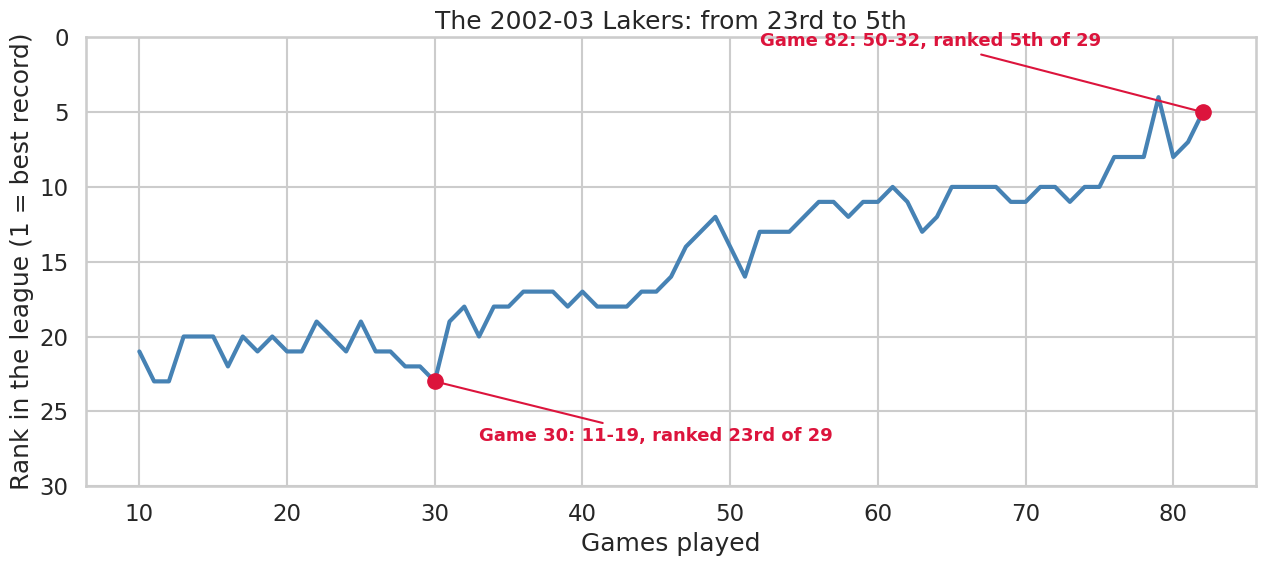

In [3]:
# CELL 3 | CHART: 2002-03 Lakers, rank in the league after each game
import seaborn as sns
sns.set_theme(style="whitegrid", context="talk")

def ordinal(n):
    return f"{n}{'th' if 10 <= n % 100 <= 20 else {1: 'st', 2: 'nd', 3: 'rd'}.get(n % 10, 'th')}"

team, season = "LAL", 2003
t = g[(g["SEASON"] == season) & (g["TEAM_ABBREVIATION"] == team)].set_index("N")
n_teams = g[g["SEASON"] == season]["TEAM_ABBREVIATION"].nunique()
rk = t["rank_N"].loc[10:82]

fig, ax = plt.subplots(figsize=(13, 6))
ax.plot(rk.index, rk.values, color="steelblue", lw=3)
ax.invert_yaxis()
ax.set_ylim(n_teams + 1, 0)
for n, dy in [(30, 2.0), (82, -2.2)]:
    r = int(t.loc[n, "rank_N"]); w = int(t.loc[n, "cumW"])
    ax.plot([n], [r], "o", color="crimson", ms=11, zorder=5)
    ax.annotate(f"Game {n}: {w}-{n - w}, ranked {ordinal(r)} of {n_teams}", (n, r), xytext=(n - 30 if n == 82 else n + 3, r + dy * 2),
                fontsize=13, fontweight="bold", color="crimson",
                arrowprops=dict(arrowstyle="-", color="crimson"))
ax.set_xlabel("Games played"); ax.set_ylabel("Rank in the league (1 = best record)")
ax.set_title("The 2002-03 Lakers: from 23rd to 5th")
plt.tight_layout(); plt.show()

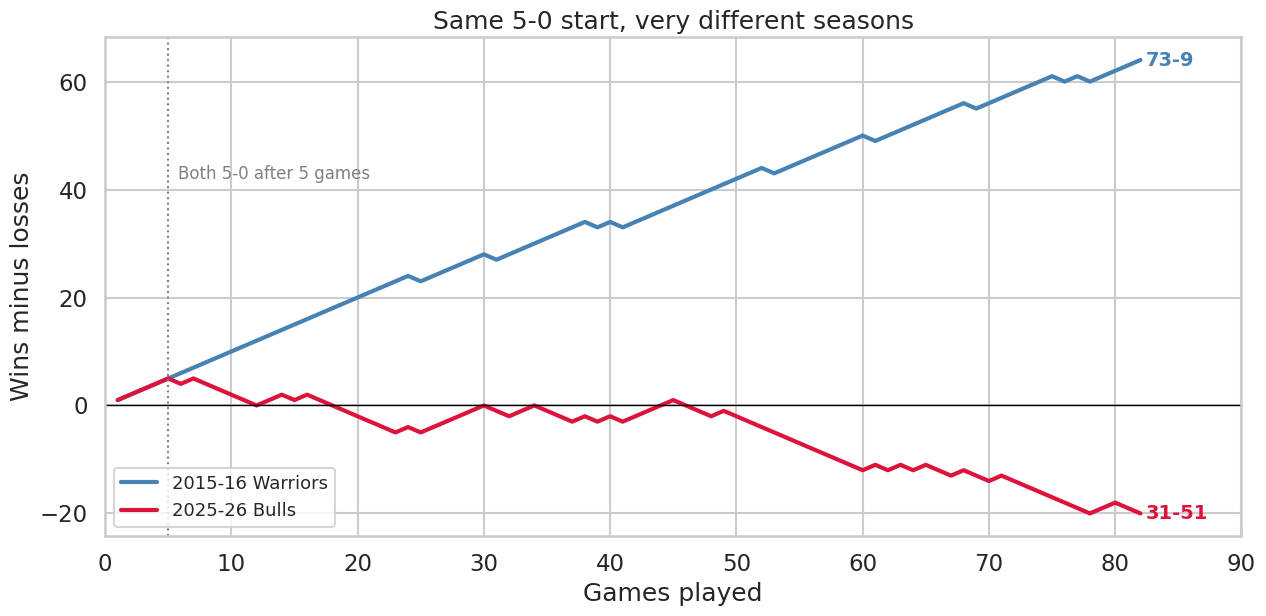

In [4]:
# CELL 4 | CHART: 2015-16 Warriors vs 2025-26 Bulls, both 5-0
fig, ax = plt.subplots(figsize=(13, 6.5))
for season, team, label, col in [(2016, "GS", "2015-16 Warriors", "steelblue"), (2026, "CHI", "2025-26 Bulls", "crimson")]:
    d = g[(g["SEASON"] == season) & (g["TEAM_ABBREVIATION"] == team)].set_index("N")
    over = 2 * d["cumW"] - d.index            # wins minus losses
    ax.plot(over.index, over.values, color=col, lw=3, label=label)
    fw = int(d.loc[82, "cumW"])
    ax.annotate(f"{fw}-{82 - fw}", (82, over.loc[82]), xytext=(4, 0), textcoords="offset points",
                color=col, fontsize=14, fontweight="bold", va="center")
ax.axhline(0, color="black", lw=1)
ax.axvline(5, color="gray", ls=":", lw=1.5)
ax.text(5.8, 42, "Both 5-0 after 5 games", color="gray", fontsize=12)
ax.set_xlim(0, 90)
ax.set_xlabel("Games played"); ax.set_ylabel("Wins minus losses")
ax.set_title("Same 5-0 start, very different seasons")
ax.legend(loc="lower left", fontsize=13)
plt.tight_layout(); plt.show()

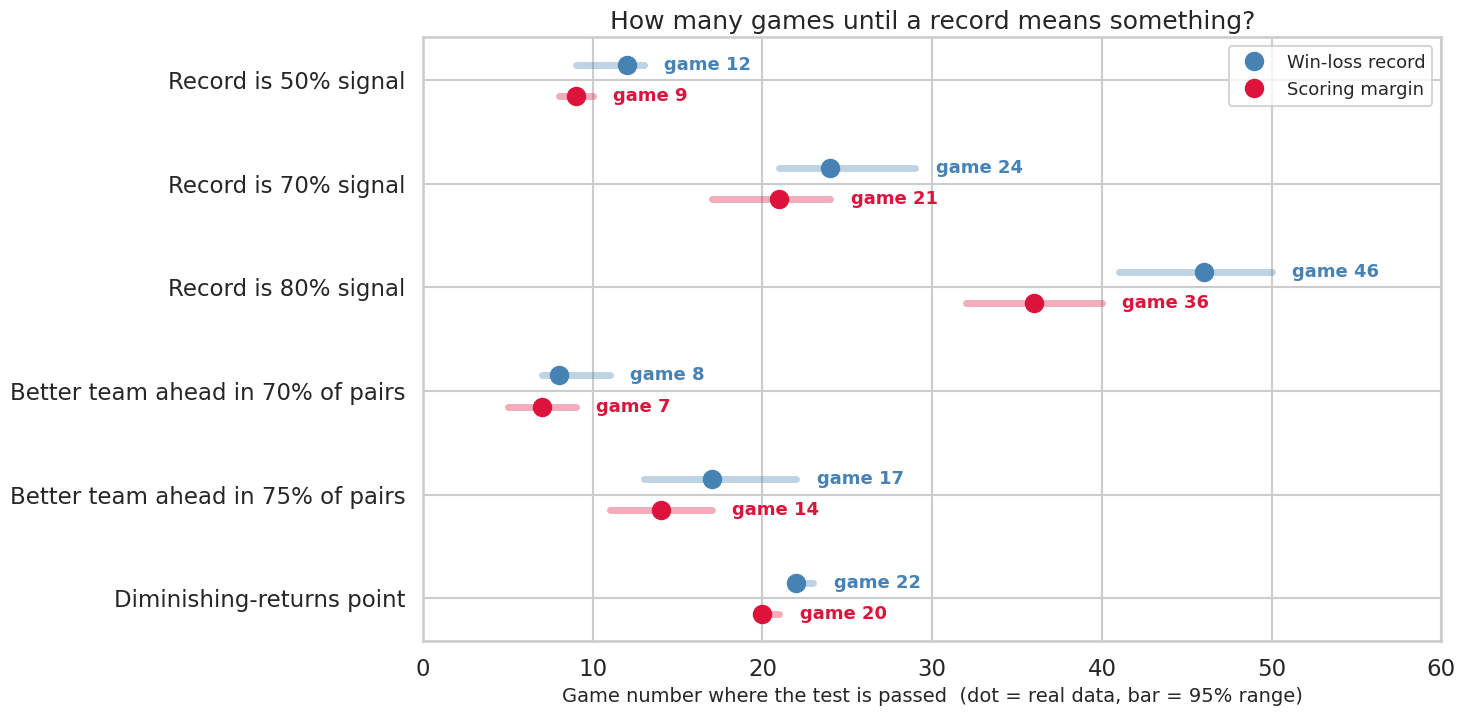

In [5]:
# CELL 5 | CHART: the headline answers with 95% ranges
import seaborn as sns
sns.set_theme(style="whitegrid", context="talk")

tests = [  # (label, win% value, win% function, margin value, margin function)
    ("Record is 50% signal",        first_cross(real["rel_wp"], 0.5),  lambda a, b: first_cross(a["rel_wp"], 0.5),
                                    first_cross(real["rel_md"], 0.5),  lambda a, b: first_cross(a["rel_md"], 0.5)),
    ("Record is 70% signal",        first_cross(real["rel_wp"], 0.7),  lambda a, b: first_cross(a["rel_wp"], 0.7),
                                    first_cross(real["rel_md"], 0.7),  lambda a, b: first_cross(a["rel_md"], 0.7)),
    ("Record is 80% signal",        first_cross(real["rel_wp"], 0.8),  lambda a, b: first_cross(a["rel_wp"], 0.8),
                                    first_cross(real["rel_md"], 0.8),  lambda a, b: first_cross(a["rel_md"], 0.8)),
    ("Better team ahead in 70% of pairs", first_cross(real_s["acc"]["rest_wp"], 0.70), lambda a, b: first_cross(b["acc"]["rest_wp"], 0.70),
                                    first_cross(real_s["acc"]["rest_md"], 0.70), lambda a, b: first_cross(b["acc"]["rest_md"], 0.70)),
    ("Better team ahead in 75% of pairs", first_cross(real_s["acc"]["rest_wp"], 0.75), lambda a, b: first_cross(b["acc"]["rest_wp"], 0.75),
                                    first_cross(real_s["acc"]["rest_md"], 0.75), lambda a, b: first_cross(b["acc"]["rest_md"], 0.75)),
    ("Diminishing-returns point",   knee(kfit_curve(real["k_wp"])),    lambda a, b: knee(kfit_curve(a["k_wp"])),
                                    knee(kfit_curve(real["k_md_theory"])), lambda a, b: knee(kfit_curve(a["k_md_theory"]))),
]

fig, ax = plt.subplots(figsize=(15, 7.5))
for i, (label, vw, fw, vm, fm) in enumerate(tests):
    y = len(tests) - 1 - i
    for v, f, col, off, name in [(vw, fw, "steelblue", 0.15, "Win-loss record"), (vm, fm, "crimson", -0.15, "Scoring margin")]:
        lo, hi = ci(f)
        ax.plot([lo, hi], [y + off, y + off], color=col, lw=5, alpha=0.35, solid_capstyle="round")
        ax.plot([v], [y + off], "o", color=col, ms=13, zorder=5, label=name if i == 0 else None)
        ax.text(hi + 1.2, y + off, f"game {v}", va="center", fontsize=13, color=col, fontweight="bold")
ax.set_yticks(range(len(tests)))
ax.set_yticklabels([t[0] for t in tests][::-1])
ax.set_xlim(0, 60)
ax.set_xlabel("Game number where the test is passed  (dot = real data, bar = 95% range)", fontsize=14)
ax.set_title("How many games until a record means something?")
ax.legend(loc="upper right", fontsize=13)
plt.tight_layout(); plt.show()

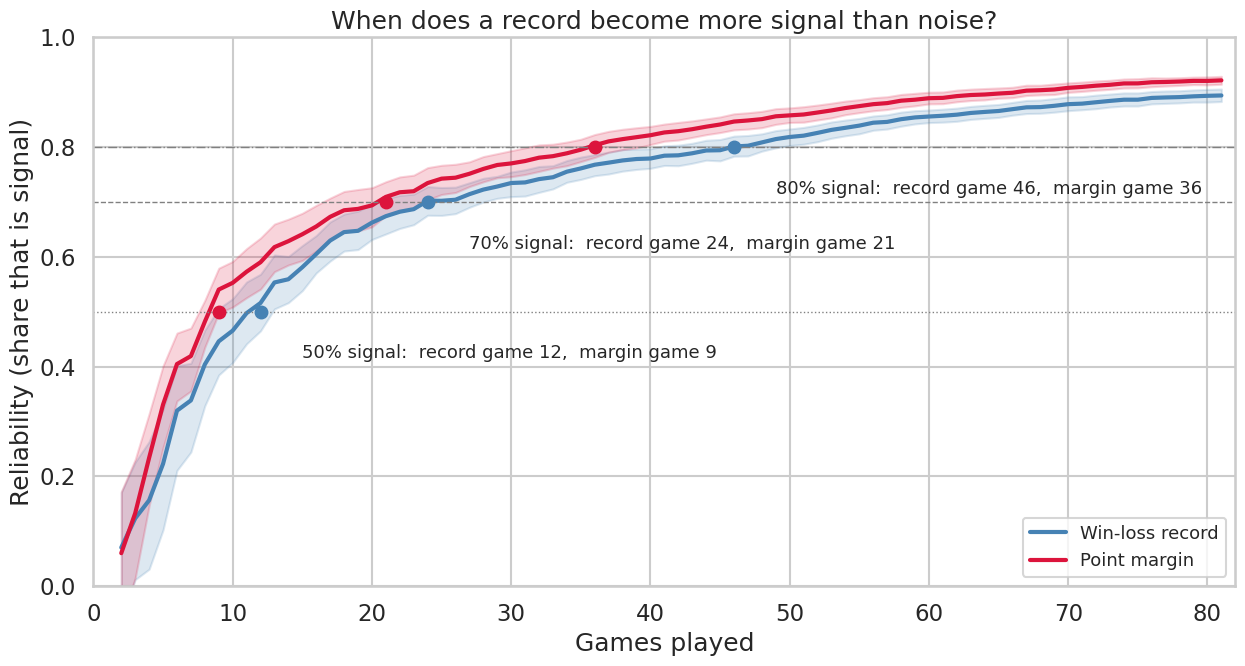

In [6]:
# CELL 6 | CHART: reliability, how much of a record is signal | Test 1
import seaborn as sns
sns.set_theme(style="whitegrid", context="talk")
n = N[:81]

def band(key):
    arr = np.array([a[key] for a, b in boot])
    return np.nanpercentile(arr, 2.5, axis=0), np.nanpercentile(arr, 97.5, axis=0)

fig, ax = plt.subplots(figsize=(13, 7))
for key, label, col in [("rel_wp", "Win-loss record", "steelblue"), ("rel_md", "Point margin", "crimson")]:
    lo, hi = band(key)
    ax.fill_between(n, lo, hi, color=col, alpha=0.18)
    ax.plot(n, real[key], color=col, lw=3, label=label)
for R, ls in [(0.5, ":"), (0.7, "--"), (0.8, "-.")]:
    x1, x2 = first_cross(real["rel_wp"], R), first_cross(real["rel_md"], R)
    ax.axhline(R, color="gray", ls=ls, lw=1)
    ax.plot([x1], [R], "o", color="steelblue", ms=9, zorder=5)
    ax.plot([x2], [R], "o", color="crimson", ms=9, zorder=5)
    ax.text(x1 + 3, R - 0.085, f"{int(R * 100)}% signal:  record game {x1},  margin game {x2}", fontsize=13)
ax.set_xlim(0, 82); ax.set_ylim(0, 1)
ax.set_xlabel("Games played"); ax.set_ylabel("Reliability (share that is signal)")
ax.set_title("When does a record become more signal than noise?")
ax.legend(loc="lower right", fontsize=13)
plt.tight_layout(); plt.show()

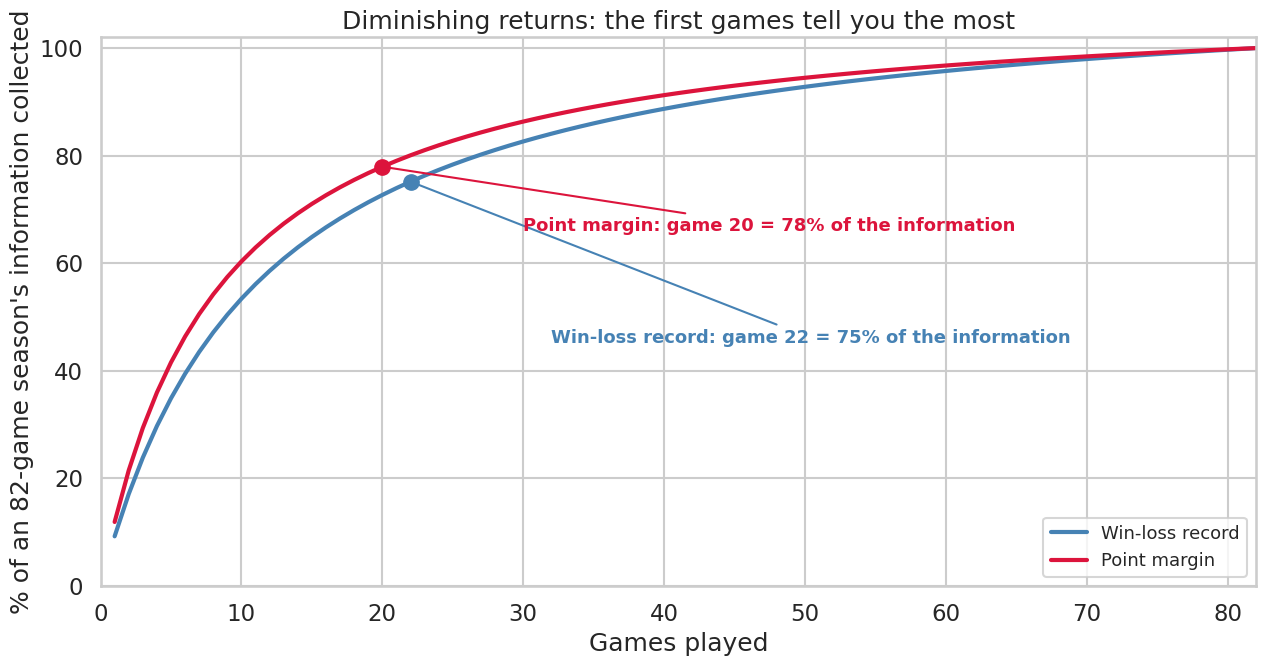

In [7]:
# CELL 7 | CHART: information collected, with the diminishing-returns point | Test 1
import seaborn as sns
sns.set_theme(style="whitegrid", context="talk")

fig, ax = plt.subplots(figsize=(13, 7))
for k, label, col, dy in [(real["k_wp"], "Win-loss record", "steelblue", -30), (real["k_md_theory"], "Point margin", "crimson", -12)]:
    share = (N / (N + k)) / (82 / (82 + k)) * 100
    ax.plot(N, share, color=col, lw=3, label=label)
    kn = knee(kfit_curve(k))
    ax.plot([kn], [share[kn - 1]], "o", color=col, ms=11, zorder=5)
    ax.annotate(f"{label}: game {kn} = {share[kn - 1]:.0f}% of the information", (kn, share[kn - 1]),
                xytext=(kn + 10, share[kn - 1] + dy), color=col, fontsize=13, fontweight="bold",
                arrowprops=dict(arrowstyle="-", color=col))
ax.set_xlim(0, 82); ax.set_ylim(0, 102)
ax.set_xlabel("Games played"); ax.set_ylabel("% of an 82-game season's information collected")
ax.set_title("Diminishing returns: the first games tell you the most")
ax.legend(loc="lower right", fontsize=13)
plt.tight_layout(); plt.show()

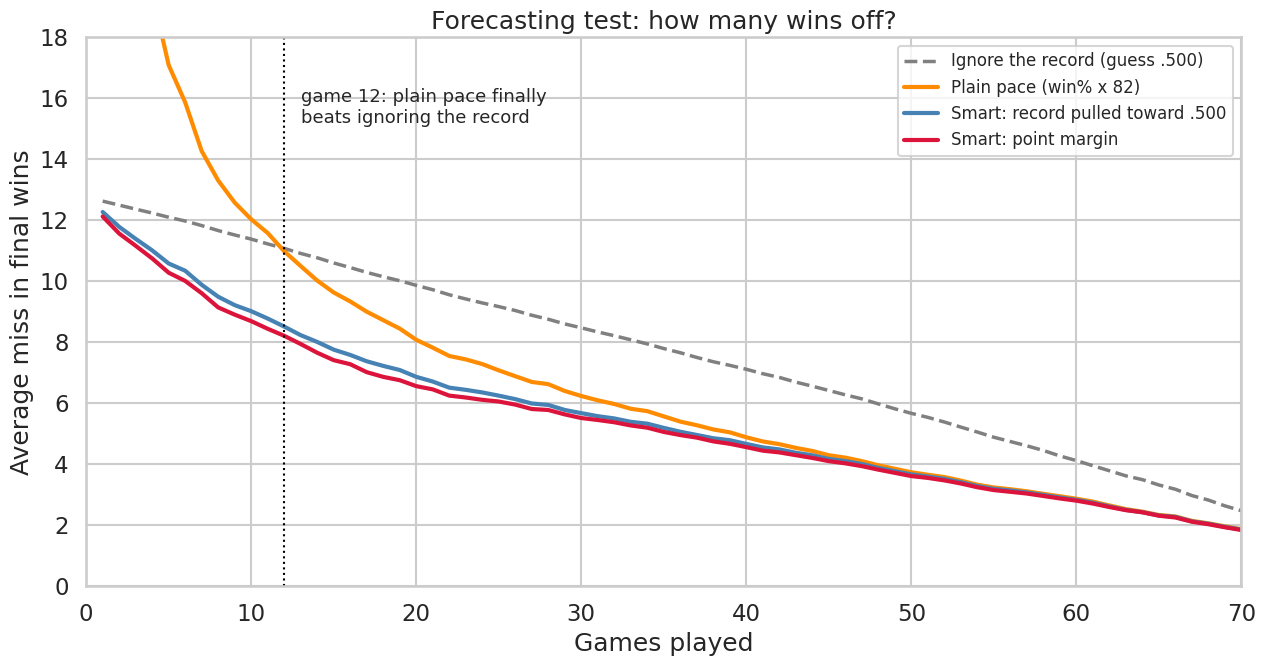

In [8]:
# CELL 8 | CHART: forecasting test, how many wins off | Test 2
import seaborn as sns
sns.set_theme(style="whitegrid", context="talk")
x = N[:81]
rm = real_s["rmse_wins"]

fig, ax = plt.subplots(figsize=(13, 7))
ax.plot(x, rm["base"], color="gray", lw=2.5, ls="--", label="Ignore the record (guess .500)")
ax.plot(x, rm["naive"], color="darkorange", lw=3, label="Plain pace (win% x 82)")
ax.plot(x, rm["lin_wp"], color="steelblue", lw=3, label="Smart: record pulled toward .500")
ax.plot(x, rm["lin_md"], color="crimson", lw=3, label="Smart: point margin")
be = real_s["naive_beats_base"]
ax.axvline(be, color="black", ls=":", lw=1.5)
ax.text(be + 1, 15.2, f"game {be}: plain pace finally\nbeats ignoring the record", fontsize=13)
ax.set_xlim(0, 70); ax.set_ylim(0, 18)
ax.set_xlabel("Games played"); ax.set_ylabel("Average miss in final wins")
ax.set_title("Forecasting test: how many wins off?")
ax.legend(loc="upper right", fontsize=12)
plt.tight_layout(); plt.show()

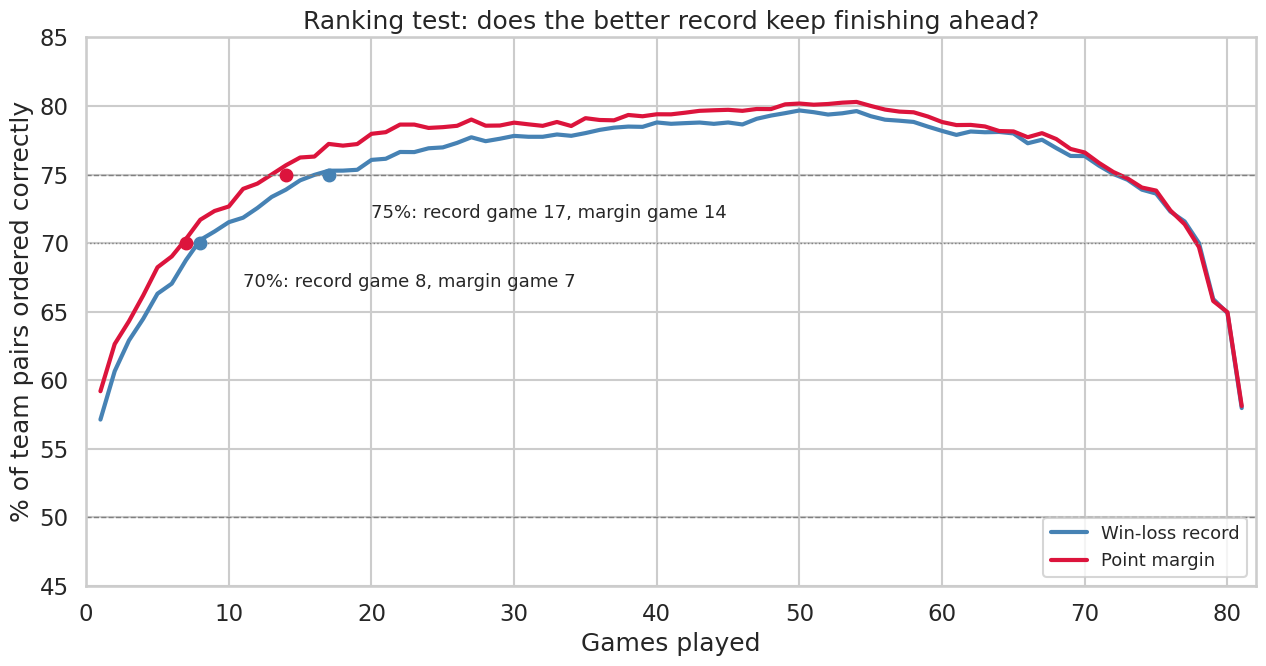

In [9]:
# CELL 9 | CHART: ranking test, does the better record keep finishing ahead | Test 3
import seaborn as sns
sns.set_theme(style="whitegrid", context="talk")
x = N[:81]
ac = real_s["acc"]

fig, ax = plt.subplots(figsize=(13, 7))
ax.plot(x, ac["rest_wp"] * 100, color="steelblue", lw=3, label="Win-loss record")
ax.plot(x, ac["rest_md"] * 100, color="crimson", lw=3, label="Point margin")
ax.axhline(50, color="gray", ls="--", lw=1)
for thr, ls in [(70, ":"), (75, "--")]:
    ax.axhline(thr, color="gray", ls=ls, lw=1)
    a1, a2 = first_cross(ac["rest_wp"], thr / 100), first_cross(ac["rest_md"], thr / 100)
    ax.plot([a1], [thr], "o", color="steelblue", ms=9, zorder=5)
    ax.plot([a2], [thr], "o", color="crimson", ms=9, zorder=5)
    ax.text(a1 + 3, thr - 3.2, f"{thr}%: record game {a1}, margin game {a2}", fontsize=13)
ax.set_xlim(0, 82); ax.set_ylim(45, 85)
ax.set_xlabel("Games played"); ax.set_ylabel("% of team pairs ordered correctly")
ax.set_title("Ranking test: does the better record keep finishing ahead?")
ax.legend(loc="lower right", fontsize=13)
plt.tight_layout(); plt.show()

In [10]:
# CELL 10 | TABLE: how much to trust a record at each game number
rows = []
for g_ in (5, 10, 15, 20, 25, 30, 40, 50, 60):
    rows.append({"game": g_,
                 "weight on the team's record": f"{g_ / (g_ + real['k_wp']):.0%}",
                 "weight on its point margin": f"{g_ / (g_ + real['k_md_theory']):.0%}"})
print("How much of a team's true level is visible after N games (the rest is the league average):")
print(pd.DataFrame(rows).set_index("game").to_string())

How much of a team's true level is visible after N games (the rest is the league average):
     weight on the team's record weight on its point margin
game                                                       
5                            31%                        38%
10                           47%                        55%
15                           57%                        65%
20                           64%                        71%
25                           69%                        75%
30                           73%                        78%
40                           78%                        83%
50                           82%                        86%
60                           84%                        88%


In [11]:
# CELL 11 | NUMBERS: the figures quoted in the article text
gm["md"] = gm.groupby(["SEASON", "TEAM_ABBREVIATION"])["MARGIN"].cumsum() / gm["N"]   # avg margin so far

# 2002-03 Lakers at game 30
x = gm[(gm["SEASON"] == 2003) & (gm["N"] == 30)].sort_values("md", ascending=False).reset_index(drop=True)
lal = x[x["TEAM_ABBREVIATION"] == "LAL"].iloc[0]
print(f"2002-03 Lakers after 30 games: {int(lal['cumW'])}-{30 - int(lal['cumW'])}, "
      f"margin {lal['md']:+.1f} per game, #{int(x.index[x['TEAM_ABBREVIATION'] == 'LAL'][0]) + 1} of {len(x)} teams in margin")

# Teams below .500 AND being outscored after 10 games: how many finished above .500?
t10 = gm[gm["N"] == 10]
grp_ = t10[(t10["cumW"] < 5) & (t10["md"] <= 0)]
print(f"Below .500 and outscored after 10 games: {len(grp_)} teams, {(grp_['final_W'] >= 42).mean():.0%} finished above .500")

# Teams below .500 after 30 games
t30 = gm[gm["N"] == 30]
b30 = t30[t30["cumW"] < 15]
print(f"Below .500 after 30 games: {len(b30)} teams, {(b30['final_rank'] <= 10).mean():.0%} finished top 10, "
      f"{(b30['final_W'] >= 50).mean():.0%} won 50+")
best = b30.sort_values("final_W", ascending=False).iloc[0]
print(f"  best comeback: {best['SEASON'] - 1}-{str(best['SEASON'])[-2:]} {best['TEAM_ABBREVIATION']} "
      f"({int(best['cumW'])}-{30 - int(best['cumW'])} at game 30, finished {int(best['final_W'])}-{82 - int(best['final_W'])})")

# Rule-of-thumb examples: projected final wins = wins so far + games left x (.500 + weight x (win% - .500))
def rule_of_thumb(w, gp, k=None):
    k = real["k_wp"] if k is None else k
    weight = gp / (gp + k)
    return w + (82 - gp) * (0.5 + weight * (w / gp - 0.5))
for label, w, gp in [("7-3 start", 7, 10), ("10-0 start (2015-16 Warriors)", 10, 10), ("6-4 start", 6, 10)]:
    print(f"{label}: pace says {w / gp * 82:.0f} wins, the rule of thumb says {rule_of_thumb(w, gp):.0f}")

2002-03 Lakers after 30 games: 11-19, margin -3.1 per game, #23 of 29 teams in margin
Below .500 and outscored after 10 games: 346 teams, 21% finished above .500
Below .500 after 30 games: 415 teams, 3% finished top 10, 1% won 50+
  best comeback: 1992-93 HOU (14-16 at game 30, finished 55-27)
7-3 start: pace says 57 wins, the rule of thumb says 50
10-0 start (2015-16 Warriors): pace says 82 wins, the rule of thumb says 63
6-4 start: pace says 49 wins, the rule of thumb says 45


In [12]:
# CELL 12 | BUILD: who each team played, then a schedule-adjusted margin (SRS-style)
old_o = pd.DataFrame({"SEASON": raw["year_id"], "TEAM_ABBREVIATION": raw["team_id"],
                      "GAME_NUM": raw["seasongame"], "OPP": raw["opp_id"]})

def load_hoopr_opp(y):
    d = pd.read_parquet(URL_HOOPR.format(y=y))
    d = d[(d["season_type"] == 2) & (d["type_abbreviation"] == "STD") & d["status_type_completed"].astype(bool)]
    d = d.sort_values("date")
    home = pd.DataFrame({"TEAM_ABBREVIATION": d["home_abbreviation"], "date": d["date"], "OPP": d["away_abbreviation"]})
    away = pd.DataFrame({"TEAM_ABBREVIATION": d["away_abbreviation"], "date": d["date"], "OPP": d["home_abbreviation"]})
    long = pd.concat([home, away]).sort_values(["TEAM_ABBREVIATION", "date"])
    long["GAME_NUM"] = long.groupby("TEAM_ABBREVIATION").cumcount() + 1
    long["SEASON"] = y
    return long[["SEASON", "TEAM_ABBREVIATION", "GAME_NUM", "OPP"]]

new_o = pd.concat([load_hoopr_opp(y) for y in range(2016, 2027) if y not in SKIP_YEARS], ignore_index=True)
opp = pd.concat([old_o, new_o], ignore_index=True)
go = gm[["SEASON", "TEAM_ABBREVIATION", "GAME_NUM"]].merge(opp, on=["SEASON", "TEAM_ABBREVIATION", "GAME_NUM"], how="left")
assert go["OPP"].notna().all(), "missing opponents"
OPP = go["OPP"].astype(str).to_numpy().reshape(-1, 82)                   # opponent of every team in every game

# opponent -> row number inside the same season
OPPI = np.zeros(OPP.shape, dtype=int)
for s in range(S):
    rows = np.where(sidx == s)[0]
    pos = {t: i for i, t in enumerate(gm["TEAM_ABBREVIATION"].astype(str).to_numpy()[::82][rows])}
    for i, r in enumerate(rows):
        OPPI[r] = [pos[t] for t in OPP[r]]

# SRS-style rating after N games: rating = avg margin + avg rating of opponents faced so far (30 passes)
srs = np.zeros((T, 81))
for s in range(S):
    rows = np.where(sidx == s)[0]
    oi = OPPI[rows]                          # opponent position among this season's teams
    for n_ in range(1, 82):
        m_ = md[rows, n_ - 1]
        r_ = m_.copy()
        for _ in range(30):
            r_ = m_ + r_[oi[:, :n_]].mean(1)
            r_ = r_ - r_.mean()
        srs[rows, n_ - 1] = r_
sos = srs - md81                              # average strength of the opponents faced so far (points per game)
print("schedule-adjusted margin built. Example: avg schedule strength spread after 20 games =",
      f"{sos[:, 19].std():.2f} pts/game")

schedule-adjusted margin built. Example: avg schedule strength spread after 20 games = 1.01 pts/game


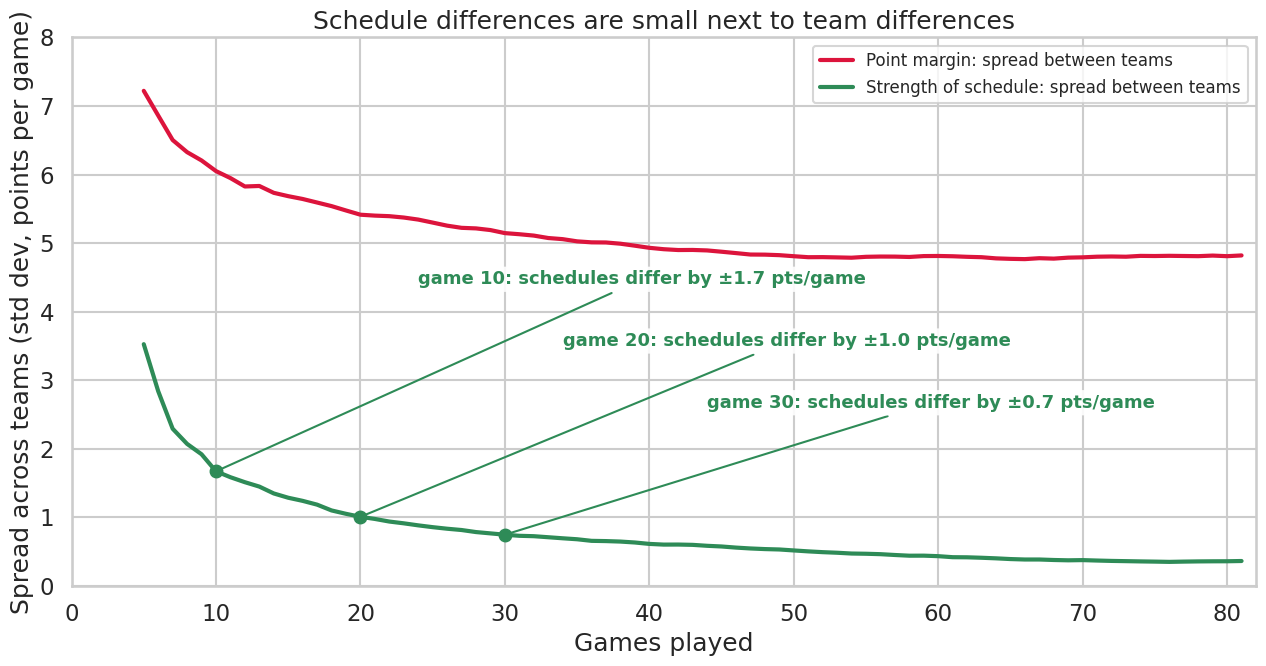

In [13]:
# CELL 13 | CHART: how much does schedule strength vary early in a season?
import seaborn as sns
sns.set_theme(style="whitegrid", context="talk")
x = N[:81]
sd_sched = sos.std(0)          # spread across teams in average opponent strength (pts per game)
sd_margin = md81.std(0)        # spread across teams in raw average margin (pts per game)
s0 = 4                         # start at game 5 (the first few games are too small a sample to draw)

fig, ax = plt.subplots(figsize=(13, 7))
ax.plot(x[s0:], sd_margin[s0:], color="crimson", lw=3, label="Point margin: spread between teams")
ax.plot(x[s0:], sd_sched[s0:], color="seagreen", lw=3, label="Strength of schedule: spread between teams")
for n_, ty in [(10, 4.4), (20, 3.5), (30, 2.6)]:
    ax.plot([n_], [sd_sched[n_ - 1]], "o", color="seagreen", ms=9, zorder=5)
    ax.annotate(f"game {n_}: schedules differ by ±{sd_sched[n_ - 1]:.1f} pts/game", (n_, sd_sched[n_ - 1]),
                xytext=(n_ + 14, ty), color="seagreen", fontsize=13, fontweight="bold",
                arrowprops=dict(arrowstyle="-", color="seagreen"),
                bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.9))
ax.set_xlim(0, 82); ax.set_ylim(0, 8)
ax.set_xlabel("Games played"); ax.set_ylabel("Spread across teams (std dev, points per game)")
ax.set_title("Schedule differences are small next to team differences")
ax.legend(loc="upper right", fontsize=12)
plt.tight_layout(); plt.show()

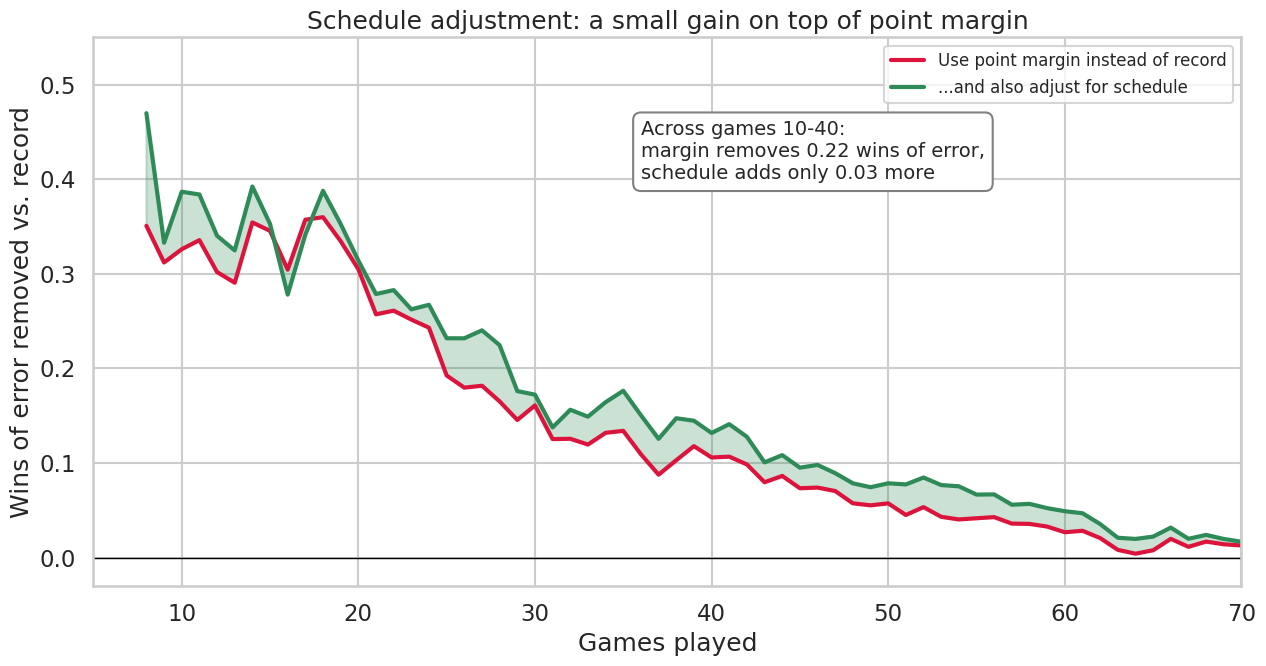

In [14]:
# CELL 14 | CHART: how many wins of forecast error does each upgrade remove?
import seaborn as sns
sns.set_theme(style="whitegrid", context="talk")
x = N[:81]

# leave-one-season-out forecast of rest-of-season win%, converted to average miss in final wins
def loso_miss(X):
    sq = np.zeros((S, 81))
    for s in range(S):
        tr, te = (sidx != s).astype(float), sidx == s
        b = wcov(X, rest, tr) / wcov(X, X, tr)
        a = wmean(rest, tr) - b * wmean(X, tr)
        sq[s] = ((rest[te] - (a + b * X[te])) ** 2).sum(0)
    return np.sqrt(sq.sum(0) / tcount.sum()) * (82 - N[:81])

m_rec, m_mar, m_adj = loso_miss(wp81), loso_miss(md81), loso_miss(srs)
gain_margin = m_rec - m_mar          # wins of error removed by using point margin instead of record
gain_sched = m_rec - m_adj           # ...and also adjusting for schedule

s0 = 7                                   # skip the first few games (too noisy to read)
fig, ax = plt.subplots(figsize=(13, 7))
ax.plot(x[s0:], gain_margin[s0:], color="crimson", lw=3, label="Use point margin instead of record")
ax.plot(x[s0:], gain_sched[s0:], color="seagreen", lw=3, label="...and also adjust for schedule")
ax.fill_between(x[s0:], gain_margin[s0:], gain_sched[s0:], color="seagreen", alpha=0.25)
lo_, hi_ = 10, 40                        # average over games 10-40
g_m, g_s = gain_margin[lo_ - 1:hi_].mean(), gain_sched[lo_ - 1:hi_].mean() - gain_margin[lo_ - 1:hi_].mean()
ax.text(36, 0.40, f"Across games {lo_}-{hi_}:\nmargin removes {g_m:.2f} wins of error,\nschedule adds only {g_s:.2f} more",
        fontsize=14, bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="gray"))
ax.axhline(0, color="black", lw=1)
ax.set_xlim(5, 70); ax.set_ylim(-0.03, 0.55)
ax.set_xlabel("Games played"); ax.set_ylabel("Wins of error removed vs. record")
ax.set_title("Schedule adjustment: a small gain on top of point margin")
ax.legend(loc="upper right", fontsize=12)
plt.tight_layout(); plt.show()

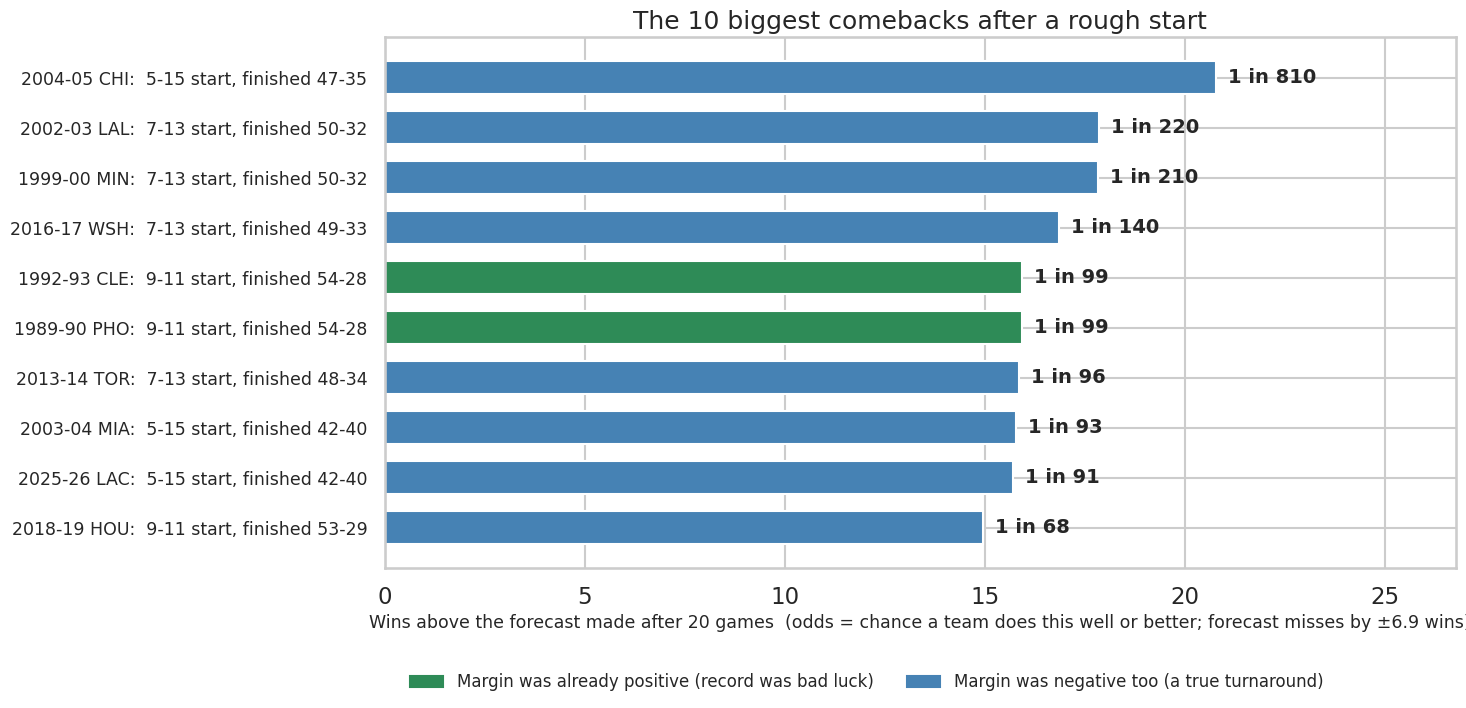

407 teams were below .500 after 20 games. Odds come from the forecast's typical miss (±6.9 wins), assuming misses follow a bell curve.


In [15]:
# CELL 15 | CHART: the 10 biggest comebacks after a rough start, with real odds
import seaborn as sns
from scipy.stats import norm
from matplotlib.patches import Patch
sns.set_theme(style="whitegrid", context="talk")
GAME = 20                                               # judge each team after 20 games
i = GAME - 1
rough = wp81[:, i] < 0.5                                # rough start = below .500 after 20 games

# expectation: leave-one-season-out forecast of final wins from the record at game 20
exp_final = np.zeros(T)
for s in range(S):
    tr, te = (sidx != s), (sidx == s)
    b, a = np.polyfit(wp81[tr, i], rest[tr, i], 1)
    exp_final[te] = cumW[te, i] + (82 - GAME) * (a + b * wp81[te, i])
beat = final_W - exp_final                              # wins above what the forecast expected
sd = beat.std()                                         # typical miss of the forecast (wins), all teams

pool = np.where(rough)[0]
ranked = pool[np.argsort(-beat[pool])][:10]
names = gm["TEAM_ABBREVIATION"].astype(str).to_numpy()[::82]

def one_in(x):
    p = 1 - norm.cdf(x / sd)                            # chance a team beats its forecast by this much or more
    n = 1 / p
    return f"1 in {int(round(n, -1)) if n >= 100 else int(round(n))}"

labels, odds, colors, vals = [], [], [], []
for t in ranked:
    yr = int(season_of[t])
    w20, l20 = int(cumW[t, i]), GAME - int(cumW[t, i])
    fw = int(final_W[t])
    labels.append(f"{yr - 1}-{str(yr)[-2:]} {names[t]}:  {w20}-{l20} start, finished {fw}-{82 - fw}")
    odds.append(one_in(beat[t]))
    colors.append("seagreen" if md[t, i] > 0 else "steelblue")
    vals.append(beat[t])

fig, ax = plt.subplots(figsize=(15, 7.5))
y = np.arange(len(ranked))[::-1]
ax.barh(y, vals, color=colors, height=0.65)
for yy, v, o in zip(y, vals, odds):
    ax.text(v + 0.3, yy, o, va="center", fontsize=14, fontweight="bold")
ax.set_yticks(y); ax.set_yticklabels(labels, fontsize=12.5)
ax.set_xlim(0, max(vals) + 6)
ax.set_xlabel(f"Wins above the forecast made after {GAME} games  (odds = chance a team does this well or better; forecast misses by ±{sd:.1f} wins)", fontsize=12.5)
ax.set_title("The 10 biggest comebacks after a rough start", fontsize=18)
ax.legend(handles=[Patch(color="seagreen", label="Margin was already positive (record was bad luck)"),
                   Patch(color="steelblue", label="Margin was negative too (a true turnaround)")],
          loc="upper center", bbox_to_anchor=(0.45, -0.17), ncol=2, fontsize=12, frameon=False)
plt.tight_layout(); plt.show()
print(f"{len(pool)} teams were below .500 after {GAME} games. Odds come from the forecast's typical miss (±{sd:.1f} wins), "
      f"assuming misses follow a bell curve.")

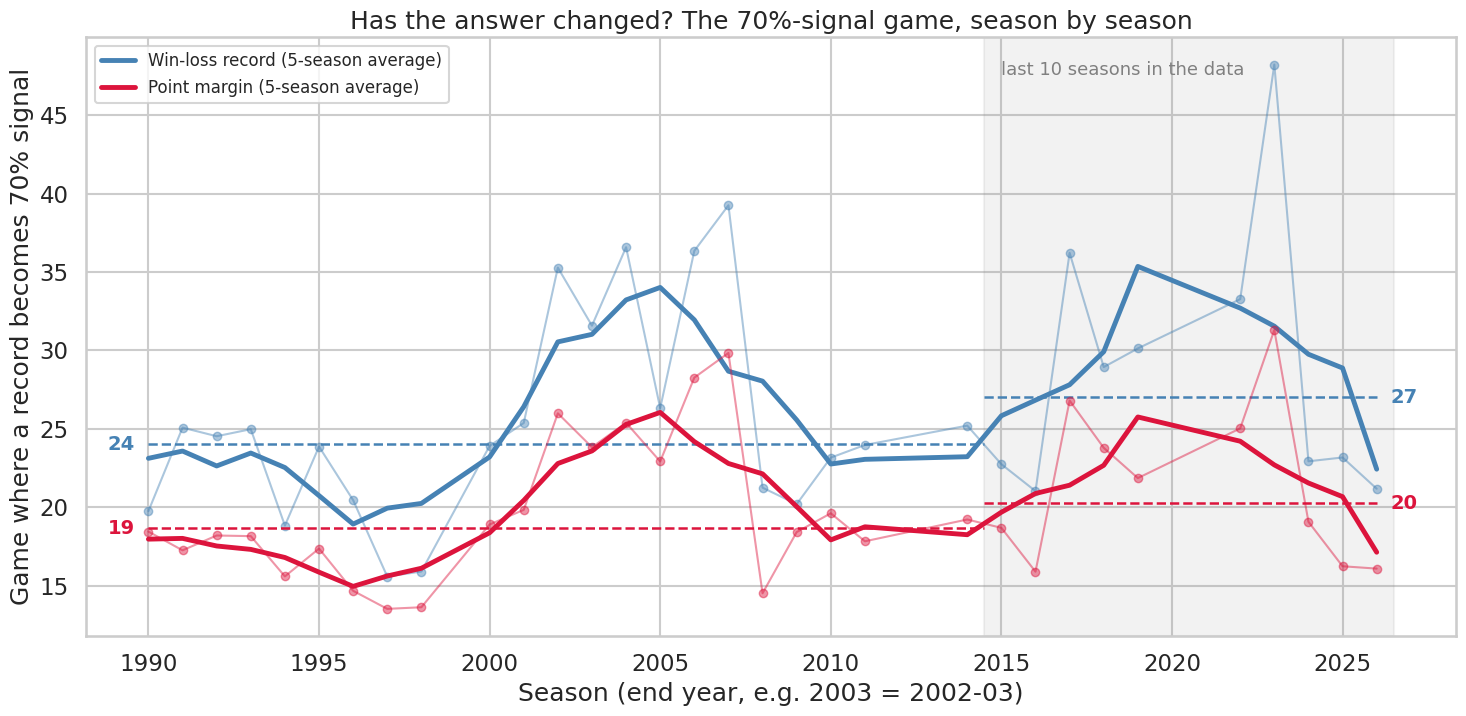

Game where a record becomes 70% signal (pooled seasons):
  Win-loss record  earlier seasons: game 24   last 10 seasons: game 27   difference +3.0 games (95% range -1.1 to +7.7)
  Point margin     earlier seasons: game 19   last 10 seasons: game 20   difference +1.6 games (95% range -1.3 to +4.4)


In [16]:
# CELL 16 | CHART: has the answer changed over time? game where a record becomes 70% signal, season by season
import seaborn as sns
sns.set_theme(style="whitegrid", context="talk")

R = 0.7
mult = R / (1 - R)                                    # games needed = k x 2.33 for 70% signal
per = []
for si, s_ in enumerate(seasons):
    w = (sidx == si).astype(float)
    r = stats(w)
    per.append({"season": int(s_), "record": r["k_wp_theory"] * mult, "margin": r["k_md_theory"] * mult})
per = pd.DataFrame(per)

# the most recent 10 seasons in the data vs. everything before
recent = per["season"] >= per["season"].sort_values().iloc[-10]
def era_game(mask, key):
    w = np.isin(sidx, np.where(mask.values)[0]).astype(float)
    r = stats(w)
    return r["k_wp_theory"] * mult if key == "record" else r["k_md_theory"] * mult
era = {k: (era_game(~recent, k), era_game(recent, k)) for k in ("record", "margin")}

fig, ax = plt.subplots(figsize=(15, 7.5))
for key, label, col in [("record", "Win-loss record", "steelblue"), ("margin", "Point margin", "crimson")]:
    ax.plot(per["season"], per[key], "o-", color=col, lw=1.5, ms=6, alpha=0.45)
    ax.plot(per["season"], per[key].rolling(5, center=True, min_periods=3).mean(), color=col, lw=3.5, label=f"{label} (5-season average)")
    first, last = per["season"].min(), per["season"].max()
    cut = per.loc[recent, "season"].min()
    ax.hlines(era[key][0], first, cut - 0.5, color=col, ls="--", lw=1.8)
    ax.hlines(era[key][1], cut - 0.5, last, color=col, ls="--", lw=1.8)
    ax.text(last + 0.4, era[key][1], f"{era[key][1]:.0f}", color=col, fontsize=14, fontweight="bold", va="center")
    ax.text(first - 0.4, era[key][0], f"{era[key][0]:.0f}", color=col, fontsize=14, fontweight="bold", va="center", ha="right")
cut = per.loc[recent, "season"].min()
ax.axvspan(cut - 0.5, per["season"].max() + 0.5, color="gray", alpha=0.10)
ax.text(cut, ax.get_ylim()[1] * 0.97, "last 10 seasons in the data", fontsize=13, color="gray", va="top")
ax.set_xlabel("Season (end year, e.g. 2003 = 2002-03)")
ax.set_ylabel("Game where a record becomes 70% signal")
ax.set_title("Has the answer changed? The 70%-signal game, season by season")
ax.legend(loc="upper left", fontsize=12)
plt.tight_layout(); plt.show()
# is the gap between eras bigger than noise? resample whole seasons inside each era 300 times
rng2 = np.random.default_rng(7)
old_ids, new_ids = np.where(~recent.values)[0], np.where(recent.values)[0]
def pooled(ids, key):
    w = np.bincount(np.concatenate([np.where(sidx == i)[0] for i in ids]), minlength=T).astype(float)
    r = stats(w)
    return (r["k_wp_theory"] if key == "record" else r["k_md_theory"]) * mult
print("Game where a record becomes 70% signal (pooled seasons):")
for key, label in [("record", "Win-loss record"), ("margin", "Point margin")]:
    diffs = [pooled(rng2.choice(new_ids, len(new_ids)), key) - pooled(rng2.choice(old_ids, len(old_ids)), key) for _ in range(300)]
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    print(f"  {label:16s} earlier seasons: game {era[key][0]:.0f}   last 10 seasons: game {era[key][1]:.0f}   "
          f"difference {era[key][1] - era[key][0]:+.1f} games (95% range {lo:+.1f} to {hi:+.1f})")

In [17]:
# CELL 17 | BUILD: net rating (points per 100 possessions) from box scores
URL_BOX = "https://raw.githubusercontent.com/sportsdataverse/hoopR-nba-data/main/nba/team_box/parquet/team_box_{y}.parquet"
BOX_YEARS = [y for y in range(1994, 2027) if y not in SKIP_YEARS]

parts_ = []
for y in BOX_YEARS:
    d = pd.read_parquet(URL_BOX.format(y=y))
    d = d[d["season_type"] == 2].drop_duplicates(["game_id", "team_id"])
    d = d[["season", "game_id", "game_date_time", "team_id", "team_abbreviation", "team_score", "opponent_team_score",
           "field_goals_attempted", "free_throws_attempted", "offensive_rebounds", "turnovers"]].copy()
    d["poss_team"] = d["field_goals_attempted"] + 0.44 * d["free_throws_attempted"] - d["offensive_rebounds"] + d["turnovers"]
    parts_.append(d)
bx = pd.concat(parts_, ignore_index=True)

# game possessions = average of the two teams' estimates (both teams get the same number)
opp_p = bx[["game_id", "team_id", "poss_team"]].rename(columns={"team_id": "opp_id", "poss_team": "poss_opp"})
bx = bx.merge(opp_p, on="game_id")
bx = bx[bx["team_id"] != bx["opp_id"]]
bx = bx.drop_duplicates(["game_id", "team_id"])
bx["POSS"] = (bx["poss_team"] + bx["poss_opp"]) / 2
bx["MARGIN"] = bx["team_score"].astype(float) - bx["opponent_team_score"].astype(float)
bx["WIN"] = (bx["MARGIN"] > 0).astype(float)
bx = bx.sort_values(["season", "team_id", "game_date_time"])
cnt = bx.groupby(["season", "team_id"])["game_id"].transform("count")
bx = bx[cnt == 82]                                            # keep complete 82-game team-seasons only
keep = bx.groupby("season")["team_id"].nunique()
bx = bx[bx["season"].isin(keep[keep >= 20].index)]            # drop seasons with too many incomplete teams

bW = bx["WIN"].values.reshape(-1, 82)
bM = bx["MARGIN"].values.reshape(-1, 82)
bP = bx["POSS"].values.reshape(-1, 82)
bseason = bx["season"].values[::82]
b_names = bx["team_abbreviation"].astype(str).to_numpy()[::82]
bseasons = np.unique(bseason)
bsidx = np.searchsorted(bseasons, bseason)

bN = np.arange(1, 83)
b_wp = bW.cumsum(1) / bN                                      # win% after N games
b_md = bM.cumsum(1) / bN                                      # point differential per game after N games
b_nr = 100 * bM.cumsum(1) / bP.cumsum(1)                      # net rating after N games (per 100 possessions)
b_pace = bP.cumsum(1) / bN                                    # possessions per game so far
b_rest = (bW.sum(1)[:, None] - bW.cumsum(1)[:, :81]) / (82 - bN[:81])

print(f"{len(bseasons)} seasons, {len(bW)} complete team-seasons with box scores")
print(f"typical possessions per game: {b_pace[:, -1].mean():.1f} (team-to-team spread within a season: ±{np.mean([b_pace[bsidx == i, -1].std() for i in range(len(bseasons))]):.1f})")

26 seasons, 743 complete team-seasons with box scores
typical possessions per game: 97.0 (team-to-team spread within a season: ±2.2)


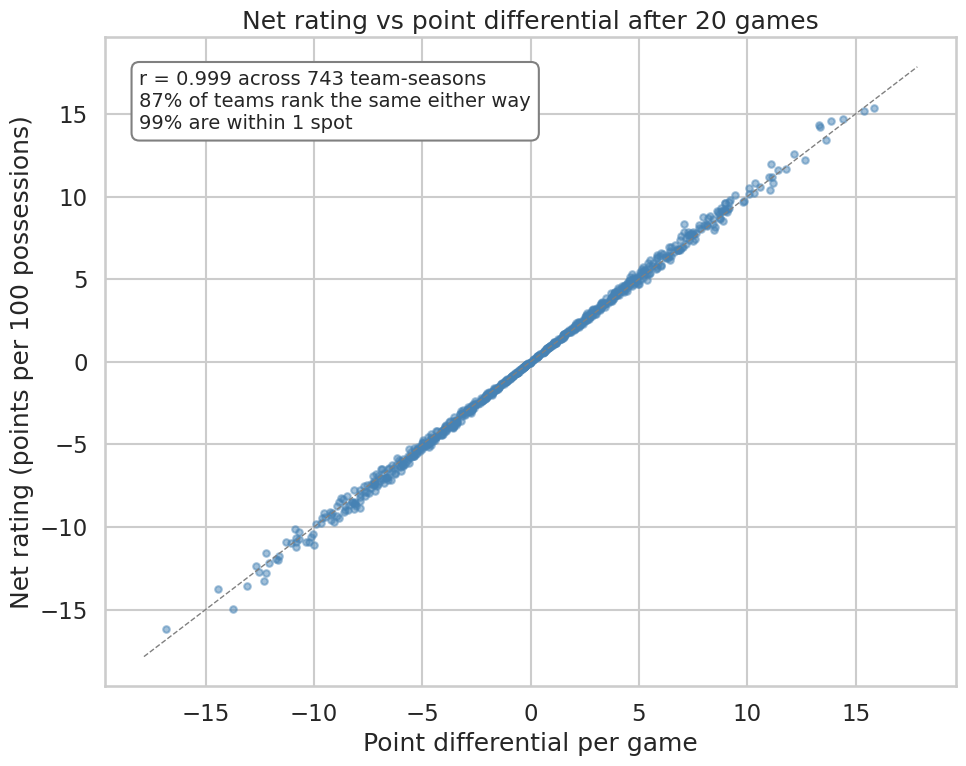

In [18]:
# CELL 18 | CHART: net rating vs point differential, every team after 20 games
import seaborn as sns
sns.set_theme(style="whitegrid", context="talk")
n_ = 20                                                       # look at the standings after 20 games
x_, y_ = b_md[:, n_ - 1], b_nr[:, n_ - 1]

# how many standings spots would change if we ranked by net rating instead of point differential?
shift = []
for i in range(len(bseasons)):
    m = bsidx == i
    shift.append(np.abs(pd.Series(x_[m]).rank(ascending=False) - pd.Series(y_[m]).rank(ascending=False)).values)
shift = np.concatenate(shift)

fig, ax = plt.subplots(figsize=(10, 8))
ax.scatter(x_, y_, s=22, color="steelblue", alpha=0.5)
lim = max(np.abs(x_).max(), np.abs(y_).max()) + 1
ax.plot([-lim, lim], [-lim, lim], color="gray", ls="--", lw=1)
ax.set_xlabel("Point differential per game"); ax.set_ylabel("Net rating (points per 100 possessions)")
ax.set_title(f"Net rating vs point differential after {n_} games")
ax.text(0.04, 0.95, f"r = {np.corrcoef(x_, y_)[0, 1]:.3f} across {len(x_)} team-seasons\n"
                    f"{(shift == 0).mean():.0%} of teams rank the same either way\n"
                    f"{(shift <= 1).mean():.0%} are within 1 spot",
        transform=ax.transAxes, va="top", fontsize=14, bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="gray"))
plt.tight_layout(); plt.show()

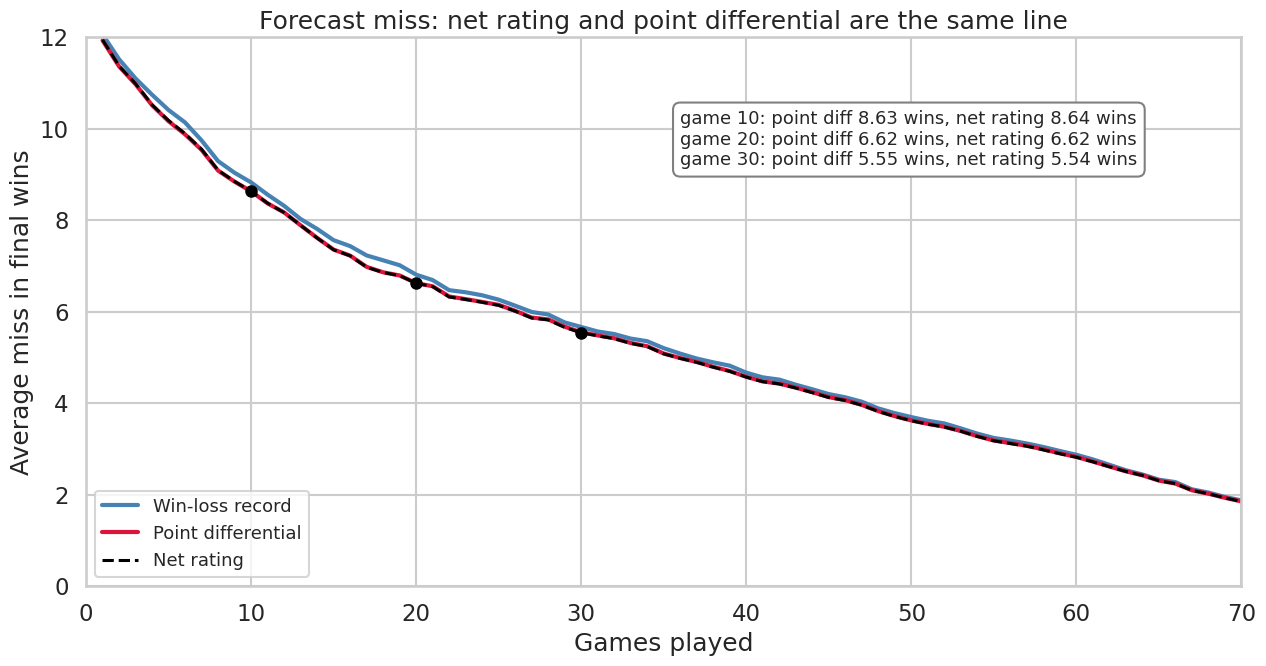

Largest gap between the two forecasts at any game from 10 to 60: 0.015 wins


In [19]:
# CELL 19 | CHART: does net rating forecast better than point differential?
import seaborn as sns
sns.set_theme(style="whitegrid", context="talk")
bS, bT = len(bseasons), len(bW)

def b_loso_miss(X):
    """leave-one-season-out forecast of rest-of-season win%, as average miss in final wins"""
    sq = np.zeros(81)
    for s in range(bS):
        tr, te = bsidx != s, bsidx == s
        for k in range(81):
            b, a = np.polyfit(X[tr, k], b_rest[tr, k], 1)
            sq[k] += ((b_rest[te, k] - (a + b * X[te, k])) ** 2).sum()
    return np.sqrt(sq / bT) * (82 - bN[:81])

m_rec, m_md, m_nr = b_loso_miss(b_wp[:, :81]), b_loso_miss(b_md[:, :81]), b_loso_miss(b_nr[:, :81])

fig, ax = plt.subplots(figsize=(13, 7))
ax.plot(bN[:81], m_rec, color="steelblue", lw=3, label="Win-loss record")
ax.plot(bN[:81], m_md, color="crimson", lw=3, label="Point differential")
ax.plot(bN[:81], m_nr, color="black", lw=2.2, ls="--", label="Net rating")
for g_ in (10, 20, 30):
    ax.plot([g_], [m_nr[g_ - 1]], "o", color="black", ms=8, zorder=5)
ax.text(36, 9.2, "\n".join(f"game {g_}: point diff {m_md[g_ - 1]:.2f} wins, net rating {m_nr[g_ - 1]:.2f} wins" for g_ in (10, 20, 30)),
        fontsize=13, bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="gray"))
ax.set_xlim(0, 70); ax.set_ylim(0, 12)
ax.set_xlabel("Games played"); ax.set_ylabel("Average miss in final wins")
ax.set_title(f"Forecast miss: net rating and point differential are the same line")
ax.legend(loc="lower left", fontsize=13)
plt.tight_layout(); plt.show()
print(f"Largest gap between the two forecasts at any game from 10 to 60: {np.abs(m_md - m_nr)[9:60].max():.3f} wins")